# Energy-preserving Bayesian operator inference - Forced Burgers 1D

Takes the data generated by `0 - Data generation - Forced Burgers 1D.ipynb` and runs the method.

1. Fit a Gaussian process to each reduced coordinate; obtain state and derivative estimates.
2. Form the row posteriors of the operator, with prior scales chosen by marginal likelihood.
3. Condition on energy preservation, exactly.
4. Sample the conditioned posterior and certify each draw.
5. Integrate the certified models and report predictions with credible bands.
6. Save to `results_Burgers1D.npz`.

## 0. Setup

In [1]:
import numpy as np
import time, warnings
from math import comb
from scipy.linalg import cho_factor, cho_solve, cholesky, null_space, block_diag, solve
from scipy.integrate import solve_ivp
from scipy.optimize import minimize
from scipy.stats import beta as beta_dist
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
import cvxpy as cp
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

D = np.load("data_Burgers1D.npz")
r  = int(D["r"]); p = 2; L = D["train_params"].shape[0]
V  = D["V"]; q_bar = D["q_bar"]; x = D["x"]; dx = float(D["dx"]); nu = float(D["nu"])
t_truth = D["t_truth"]; t_est = D["t_est"]; m_prime = t_est.size
obs_times = D["obs_times"]; Qobs = D["snapshots_compressed"]; inputs_est = D["inputs_est"]
TRAIN = D["train_params"]; TEST = D["test_params"]
TRUTH_TR = D["truth_train"]; TRUTH_TE = D["truth_test"]
T_TRAIN = 1.0

dof = 1 + r + r*(r+1)//2 + p          # d = length of the feature vector
n   = r*dof                            # length of theta
n_c = comb(r+2, 3)                     # number of EP constraints

# The quadratic term is stored compactly: only the products q_j q_k with j <= k,
# in the order given by PAIRS.  PAIRS_IJ is the same thing as two index arrays,
# which lets kron_compact pick those products out of the full outer product.
PAIRS_IJ = np.triu_indices(r)
PAIRS    = list(zip(*PAIRS_IJ))        # [(0,0), (0,1), ..., (r-1,r-1)]

def kron_compact(q):
    """The compact Kronecker product of q with itself: the products q_j q_k, j <= k."""
    return np.outer(q, q)[PAIRS_IJ]

N_SAMP = 3000      # posterior draws used for the certificate
N_PRED = 200       # certified draws integrated for prediction
DELTA  = 0.0       # certificate margin
SEED   = 20261012
ubar   = float(np.abs(TRAIN).max())

print(f"nu = {nu:g},  r = {r},  d = {dof},  n = r*d = {n},  n_c = {n_c}")
print(f"L = {L} trajectories,  m' = {m_prime} estimation times,  ubar = {ubar}")
print(f"compact quadratic terms per row: {len(PAIRS)} = r(r+1)/2")

nu = 0.01,  r = 8,  d = 47,  n = r*d = 376,  n_c = 120
L = 5 trajectories,  m' = 120 estimation times,  ubar = 1.4
compact quadratic terms per row: 36 = r(r+1)/2


## 1. Gaussian process state and derivative estimates

Each reduced coordinate is modelled by an independent GP, $\hat q_i\sim\mathcal{GP}(0,\kappa)$,
with a squared-exponential kernel and a noise term. Differentiation is linear, so the posterior
of the derivative is Gaussian too: with $\mathbf K=\kappa(\mathbf t,\mathbf t)+\sigma_n^2\mathbf I$,

$$
\tilde z(t') = \partial_{t'}\kappa(t',\mathbf t)\,\mathbf K^{-1}\mathbf y,
\qquad
\operatorname{Var}\,\tilde z(t') = \partial_{t'}\partial_{t''}\kappa(t',t'')\big|_{t''=t'}
 - \partial_{t'}\kappa(t',\mathbf t)\,\mathbf K^{-1}\partial_{t'}\kappa(t',\mathbf t)^\top .
\tag{1}
$$

The $m'$ derivative estimates are determined by only $m$ observations, so their joint covariance
is numerically rank deficient and cannot be inverted. We weight each estimation point by its own
posterior variance, $w = 1/\operatorname{Var}\tilde z$.

In [2]:
def fit_gp(t, y, seed=1):
    # kappa(t,t') = sf2 * exp(-(t-t')^2 / (2 ell^2))  +  sn2 * delta_{t,t'}
    #   ConstantKernel -> sf2, the signal variance (RBF alone has unit variance)
    #   RBF            -> ell, the correlation length in time
    #   WhiteKernel    -> sn2, the observation noise variance, on the diagonal only
    # The pair after each starting value is the box the hyperparameter is optimized
    # in.  The lower bound on ell is the one that matters: the mean spacing of the
    # m observations is about 1/30, and with no floor the fit can shrink ell below
    # that spacing, interpolate the noise, and return a derivative that is noise.
    k = (ConstantKernel(1.0, (1e-3, 1e3)) * RBF(0.2, (1e-2, 1e1))
         + WhiteKernel(1e-4, (1e-10, 1e0)))
    # fit() does one thing: it maximizes the log marginal likelihood over
    # (sf2, ell, sn2).  The predictions are done by hand in gp_estimates below,
    # because sklearn has no derivative method.
    #   normalize_y=False  - those formulas assume a zero prior mean on the raw
    #       scale, and sklearn's rescaling is undone only inside predict(), which
    #       is never called.  The reduced coordinates are already zero mean.
    #   n_restarts_optimizer - the likelihood is typically bimodal: "long ell and
    #       large sn2" (the series is all noise) against "short ell and small sn2"
    #       (interpolate every point).  One descent can land in either.
    g = GaussianProcessRegressor(kernel=k, normalize_y=False,
                                 n_restarts_optimizer=3, random_state=seed)
    return g.fit(t[:, None], y)      # t[:, None]: sklearn wants one row per sample

def gp_estimates(g, t_obs, y, t_new):
    """State estimate, derivative estimate and derivative variance at t_new, eq. (1)."""
    # The fitted hyperparameters.  k1 is the product, k1.k1 / k1.k2 its two
    # factors, k2 the WhiteKernel; the trailing underscore marks the fitted kernel.
    sf2 = float(g.kernel_.k1.k1.constant_value)
    ell = float(g.kernel_.k1.k2.length_scale)
    sn2 = float(g.kernel_.k2.noise_level)

    # Dm[a, b] = t_new[a] - t_obs[b]:  every estimation time against every
    # observation time.  This is the argument d = t' - t of the kernel.
    Dm = t_new[:, None] - t_obs[None, :]

    # K  (m x m):   covariance among the OBSERVATIONS, so sn2 is on its diagonal.
    # Ks (m' x m):  covariance of the latent function at t_new with the
    #               observations.  No noise term here: white noise is uncorrelated
    #               with the function, which is what makes the GP denoise the data
    #               rather than interpolate it.
    K  = sf2*np.exp(-0.5*((t_obs[:, None] - t_obs[None, :])/ell)**2) \
         + sn2*np.eye(t_obs.size)
    Ks = sf2*np.exp(-0.5*(Dm/ell)**2)

    # Differentiation is linear, so (q, dq/dt) is jointly Gaussian and the
    # cross-covariance is the derivative of the kernel,
    #     d kappa / dt' = kappa * (-(t' - t) / ell^2) .
    # This is why the kernel has to be differentiable at all.
    Kd = Ks * (-Dm/ell**2)

    # K is symmetric positive definite (sn2 > 0), so one Cholesky serves every
    # solve below; K is never inverted explicitly.
    K_factored = cho_factor(K, lower=True)
    alpha      = cho_solve(K_factored, y)               # alpha = K^-1 y

    state      = Ks @ alpha      # posterior mean of q at t_new
    derivative = Kd @ alpha      # posterior mean of dq/dt at t_new; this is also
                                 # exactly d/dt' of (Ks @ alpha), since alpha does
                                 # not depend on t'

    # Var[dq/dt] = prior variance - explained part.  The prior variance of the
    # slope is d^2 kappa / dt' dt'' at coincident points, which is sf2 / ell^2.
    #
    # The explained part is the DIAGONAL of Kd K^-1 Kd^T.  Only the diagonal is
    # formed: the m' derivative estimates are a linear image of m observations, so
    # the full (m' x m') covariance has rank at most m and cannot be inverted.
    # Each estimation point is therefore weighted on its own.
    K_inv_KdT = cho_solve(K_factored, Kd.T)             # (m x m'),  = K^-1 Kd^T
    explained = np.sum(Kd * K_inv_KdT.T, axis=1)        # row a of Kd dotted with
                                                        # column a of K^-1 Kd^T
    variance  = sf2/ell**2 - explained

    # The floor guards against cancellation, since 1/variance becomes a weight.
    return state, derivative, np.maximum(variance, 1e-12)

t0 = time.time()
# One independent scalar GP per trajectory and per reduced coordinate, L*r in all.
# Independent rather than vector valued: each coordinate has its own time scale and
# its own effective noise level after compression, and the operator posterior
# factorizes row by row anyway, so no cross-coordinate covariance would survive.
STATE = np.zeros((L, r, m_prime)); DERIV = np.zeros((L, r, m_prime)); DVAR = np.zeros((L, r, m_prime))
KERN = []                                    # fitted kernels, kept for inspection
for l in range(L):
    for i in range(r):
        # Qobs is the noisy compressed data: the only thing the method may see.
        g = fit_gp(obs_times[l], Qobs[l, i])
        STATE[l,i], DERIV[l,i], DVAR[l,i] = gp_estimates(g, obs_times[l], Qobs[l,i], t_est)
        KERN.append((l, i, g.kernel_))
print(f"{L*r} GP fits in {time.time()-t0:.1f} s")
print(f"derivative std: {np.sqrt(DVAR).min():.3e} .. {np.sqrt(DVAR).max():.3e}")
# DVAR becomes the regression weights W_i = diag(1/Var) of section 2, so estimates
# the GP is unsure about are discounted there automatically.

40 GP fits in 1.8 s
derivative std: 2.031e-02 .. 1.263e+00


In [3]:
STATE.shape, DERIV.shape, DVAR.shape

((5, 8, 120), (5, 8, 120), (5, 8, 120))

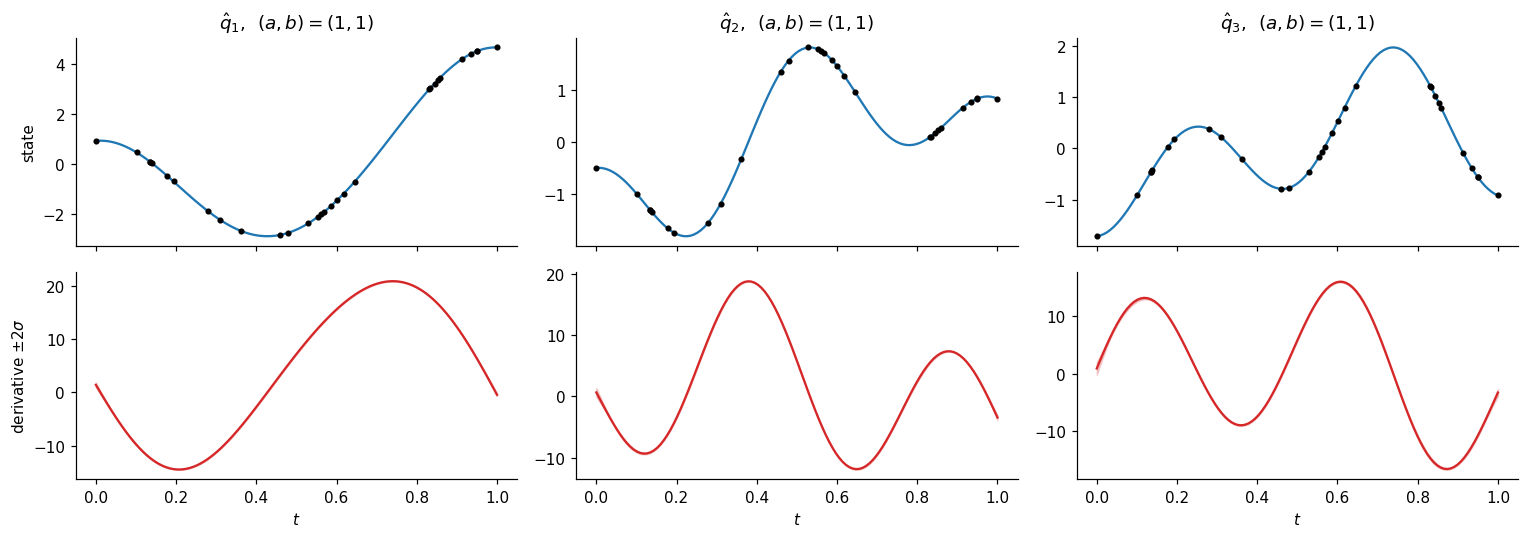

In [4]:
# GP fits for the first three coordinates of one trajectory, against the data.
l = 4
fig, axes = plt.subplots(2, 3, figsize=(14, 5), sharex=True)
for i in range(3):
    axes[0,i].plot(t_est, STATE[l,i], "C0")
    axes[0,i].plot(obs_times[l], Qobs[l,i], "ko", ms=3)
    axes[0,i].set_title(rf"$\hat q_{{{i+1}}}$,  $(a,b)=({TRAIN[l][0]:g}, {TRAIN[l][1]:g})$")
    axes[1,i].plot(t_est, DERIV[l,i], "C3")
    axes[1,i].fill_between(t_est, DERIV[l,i]-2*np.sqrt(DVAR[l,i]),
                           DERIV[l,i]+2*np.sqrt(DVAR[l,i]), color="C3", alpha=.2)
    axes[1,i].set_xlabel("$t$")
axes[0,0].set_ylabel("state"); axes[1,0].set_ylabel("derivative $\\pm 2\\sigma$")
plt.tight_layout(); plt.show()

## 2. The operator posterior

With feature vector $\mathbf d(\hat{\mathbf q},\mathbf u)=[1;\ \hat{\mathbf q};\ \hat{\mathbf q}\,\hat\otimes\,\hat{\mathbf q};\ \mathbf u]\in\mathbb R^{d}$
and $\widetilde{\mathbf D}$ the matrix of features at the estimation times of all trajectories,
each row $\hat{\mathbf o}_i$ of the operator matrix has the Gaussian posterior

$$
\hat{\mathbf o}_i\mid\text{data}\sim\mathcal N(\boldsymbol\mu_i,\boldsymbol\Sigma_i),
\qquad
\boldsymbol\Sigma_i=\bigl(\widetilde{\mathbf D}^\top\mathbf W_i\widetilde{\mathbf D}+\boldsymbol\Gamma_i^2\bigr)^{-1},
\qquad
\boldsymbol\mu_i=\boldsymbol\Sigma_i\widetilde{\mathbf D}^\top\mathbf W_i\tilde{\mathbf z}_i .
\tag{2}
$$

In [5]:
def features(q, u):
    """The feature vector d(q,u) = [1; q; q (x) q; u]."""
    return np.concatenate(([1.0], q, kron_compact(q), u))

# D~: one row per trajectory and estimation time, the same for every operator row.
Dtil = np.zeros((L*m_prime, dof))
for l in range(L):
    for k in range(m_prime):
        Dtil[l*m_prime + k] = features(STATE[l, :, k], inputs_est[l, :, k])

# The model as one linear-Gaussian system, z~ = Phi theta + e with e ~ N(0, W^-1):
#   theta = [o_1; ...; o_r],   Phi = blkdiag(D~, ..., D~),   W = diag(wvec).
# Each operator row sees the same features but its own GP derivative variances.
zvec = np.concatenate([DERIV[:, i, :].reshape(-1) for i in range(r)])      # z~
wvec = np.concatenate([1.0/DVAR[:, i, :].reshape(-1) for i in range(r)])   # diag W
Nobs = zvec.size
Phi  = block_diag(*([Dtil]*r))

# Phi^T W Phi is block diagonal and Phi^T W z~ splits by row, which is what makes
# the posterior (2) row by row.  Block i of each:
DWD = np.zeros((r, dof, dof)); DWz = np.zeros((r, dof))
for i in range(r):
    for l in range(L):
        Dl = Dtil[l*m_prime:(l+1)*m_prime]      # the rows of D~ for trajectory l
        wl = 1.0/DVAR[l, i]                     # the weights of row i there
        DWD[i] += Dl.T @ (wl[:, None]*Dl)
        DWz[i] += Dl.T @ (wl*DERIV[l, i])
print(f"D~ {Dtil.shape}, cond {np.linalg.cond(Dtil):.2e}")
print(f"Phi {Phi.shape},  N = {Nobs} observations,  n = {n} unknowns")

D~ (600, 47), cond 2.85e+04
Phi (4800, 376),  N = 4800 observations,  n = 376 unknowns


### 2.1 Prior scales by marginal likelihood

The prior is $\hat{\mathbf o}_i\sim\mathcal N(\mathbf 0,\boldsymbol\Gamma_i^{-2})$ with one scale
$\gamma_b$ per block of the operator ($\hat{\mathbf c},\widehat{\mathbf A},\widehat{\mathbf H},\widehat{\mathbf B}$).
They are chosen by maximising the log evidence of the linear-Gaussian model
$\tilde{\mathbf z}=\boldsymbol\Phi\boldsymbol\theta+\mathbf e$,
$\mathbf e\sim\mathcal N(\mathbf 0,\mathbf W^{-1})$,
$\boldsymbol\theta\sim\mathcal N(\mathbf 0,\mathbf P_0^{-1})$, which is available in closed form:

$$
\log p(\tilde{\mathbf z})
 = -\tfrac N2\log2\pi
 + \tfrac12\log|\mathbf W|
 + \tfrac12\log|\mathbf P_0|
 - \tfrac12\log|\mathbf P|
 - \tfrac12\bigl(\tilde{\mathbf z}^\top\mathbf W\tilde{\mathbf z}-\boldsymbol\mu^\top\mathbf P\boldsymbol\mu\bigr),
\tag{3}
$$

with $\mathbf P=\boldsymbol\Phi^\top\mathbf W\boldsymbol\Phi+\mathbf P_0$ and
$\boldsymbol\mu=\mathbf P^{-1}\boldsymbol\Phi^\top\mathbf W\tilde{\mathbf z}$.

The scales must be selected under the *constrained* model: selecting them for the unconstrained
one and then conditioning is not the same thing. Writing $\mathbf T$ for a basis of
$\ker\mathbf C$ (built in section 3), the constraint is imposed by the substitution
$\boldsymbol\theta=\mathbf T\mathbf z$, so (3) is applied with
$\boldsymbol\Phi\to\boldsymbol\Phi\mathbf T$ and
$\mathbf P_0=\mathbf T^\top\boldsymbol\Sigma_0^{-1}\mathbf T$,
$\boldsymbol\Sigma_0^{-1}=\operatorname{diag}(\boldsymbol\gamma^2)$.

## 3. Energy preservation

### 3.1 The constraint

$\widehat{\mathbf H}$ is energy preserving iff $H_{ijk}+H_{jik}+H_{kij}=0$ for all $i,j,k$, which is
one linear equation per cubic monomial. In compact coefficients these read
$h_{a,aa}=0$, $h_{a,ac}+h_{c,aa}=0$, $h_{a,cc}+h_{c,ac}=0$ and
$h_{a,bc}+h_{b,ac}+h_{c,ab}=0$. Collected into a matrix acting on
$\boldsymbol\theta=[\hat{\mathbf o}_1;\dots;\hat{\mathbf o}_r]$,

$$
\widehat{\mathbf H}\in\mathcal H_{\mathrm{EP}}\iff \mathbf C\boldsymbol\theta=\mathbf 0,
\qquad \mathbf C\in\mathbb R^{n_c\times n},\quad \operatorname{rank}\mathbf C=n_c .
\tag{4}
$$

In [6]:
def index_of_h(i, j, k):
    """Where the compact coefficient h_{i,jk} sits inside theta.

    Row i of the operator starts at i*dof and is laid out as
    [c_i, A_i (r entries), H_i (compact, r(r+1)/2 entries), B_i (p entries)],
    so the quadratic part starts at i*dof + 1 + r.  h_{i,jk} = h_{i,kj}, so the
    pair is sorted before it is looked up in PAIRS.
    """
    pair = (min(j, k), max(j, k))
    return i*dof + 1 + r + PAIRS.index(pair)

# One row of C per cubic monomial q_a q_b q_c with a <= b <= c.  Each row is built
# as a full vector of length n with a 1 in each position the equation refers to.
rows = []

for a in range(r):                                   # q_a^3:  h_{a,aa} = 0
    row = np.zeros(n)
    row[index_of_h(a, a, a)] += 1.0
    rows.append(row)

for a in range(r):
    for c in range(a+1, r):
        row = np.zeros(n)                            # q_a^2 q_c
        row[index_of_h(a, a, c)] += 1.0
        row[index_of_h(c, a, a)] += 1.0
        rows.append(row)

        row = np.zeros(n)                            # q_a q_c^2
        row[index_of_h(a, c, c)] += 1.0
        row[index_of_h(c, a, c)] += 1.0
        rows.append(row)

for a in range(r):                                   # q_a q_b q_c, all distinct
    for b in range(a+1, r):
        for c in range(b+1, r):
            row = np.zeros(n)
            row[index_of_h(a, b, c)] += 1.0
            row[index_of_h(b, a, c)] += 1.0
            row[index_of_h(c, a, b)] += 1.0
            rows.append(row)

Cmat = np.array(rows)
print(f"C: {Cmat.shape},  expected n_c = {n_c},  rank = {np.linalg.matrix_rank(Cmat)}")
print(f"nonzeros per row: {Cmat.astype(bool).sum(1).min()} to {Cmat.astype(bool).sum(1).max()}")

# T: an orthonormal basis of ker C, so that theta = T z satisfies C theta = 0.
Tker = null_space(Cmat)
print(f"ker C: {Tker.shape} (expected {n - n_c}),  ||C T|| = {np.abs(Cmat@Tker).max():.2e}")

C: (120, 376),  expected n_c = 120,  rank = 120
nonzeros per row: 1 to 3
ker C: (376, 256) (expected 256),  ||C T|| = 3.33e-16


In [7]:
Cmat.sum(axis=1), max(Cmat.sum(axis=0))

(array([1., 1., 1., 1., 1., 1., 1., 1., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
        2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
        2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
        2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 3., 3., 3., 3.,
        3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
        3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
        3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
        3.]),
 np.float64(1.0))

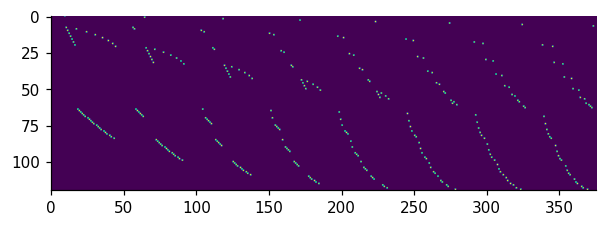

In [8]:
plt.imshow(Cmat)

In [9]:
# --- prior scales by marginal likelihood, eq. (3) ---
# Sigma_0^{-1} = diag(gamma^2): one scale per operator block, the same pattern
# repeated for each of the r rows of theta = [o_1; ...; o_r].
def prior_scales(gam):
    g_c, g_A, g_H, g_B = gam
    one_row = np.concatenate(([g_c],
                              np.full(r, g_A),
                              np.full(r*(r+1)//2, g_H),
                              np.full(p, g_B)))
    return np.tile(one_row, r)             # one entry per component of theta

# Constrained coordinates theta = T z, so eq. (3) is applied with Phi -> Phi T.
# The parts that do not depend on gamma are formed once.
PhiT       = Phi @ Tker
PhiT_W_PhiT = PhiT.T @ (wvec[:, None]*PhiT)    # (Phi T)^T W (Phi T)
PhiT_W_z    = PhiT.T @ (wvec*zvec)             # (Phi T)^T W z~
z_W_z       = zvec @ (wvec*zvec)               # z~^T W z~
logdet_W    = np.sum(np.log(wvec))             # log|W|, W being diagonal

def log_evidence(gam):
    """Eq. (3) in the coordinates of ker C."""
    gamma_sq = prior_scales(gam)**2                     # diagonal of Sigma_0^-1
    P0 = Tker.T @ (gamma_sq[:, None] * Tker)            # T^T Sigma_0^-1 T
    P  = PhiT_W_PhiT + P0

    sign0, logdet_P0 = np.linalg.slogdet(P0)
    signP, logdet_P  = np.linalg.slogdet(P)
    if sign0 <= 0 or signP <= 0:
        return -1e12                   # gamma so small that P0 is numerically singular

    mu = solve(P, PhiT_W_z, assume_a="pos")             # P^-1 (Phi T)^T W z~

    return (-0.5*Nobs*np.log(2*np.pi)
            + 0.5*logdet_W
            + 0.5*logdet_P0
            - 0.5*logdet_P
            - 0.5*(z_W_z - mu @ (P @ mu)))

def objective(log_gamma):
    """What the optimizer minimizes: minus eq. (3), as a function of log gamma.

    In log gamma, so that gamma > 0 needs no constraint and one step is one step
    in scale.
    """
    return -log_evidence(np.exp(log_gamma))

# Nelder-Mead because only function values are compared, and three starts because
# the evidence is very flat in gamma_c.
t0 = time.time()
best = None
for log_gamma_0 in ([-2.]*4, [0.]*4, [2.]*4):            # gamma = 0.14, 1, 7.4
    result = minimize(objective, log_gamma_0, method="Nelder-Mead",
                      options=dict(xatol=1e-4, fatol=1e-3, maxfev=2000))
    if best is None or result.fun < best.fun:
        best = result
gamma = np.exp(best.x)
print(f"evidence maximised in {time.time()-t0:.1f} s,  log p(z~) = {-best.fun:.2f}")
for name, g in zip(["c", "A", "H", "B"], gamma):
    print(f"   gamma_{name} = {g:.4f}")

evidence maximised in 1.0 s,  log p(z~) = 5226.70
   gamma_c = 0.7418
   gamma_A = 0.4683
   gamma_H = 1.0063
   gamma_B = 0.1591


In [10]:
gamma

array([0.74179334, 0.46831469, 1.00634445, 0.15909526])

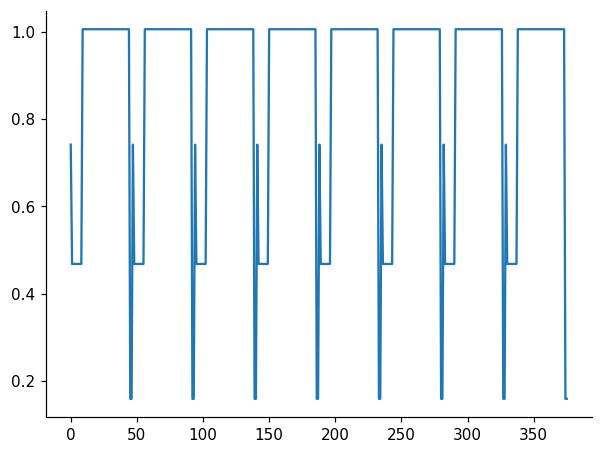

In [11]:
gvec = prior_scales(gamma)
plt.plot(gvec)

In [12]:
# --- row posteriors, eq. (2) ---
gvec = prior_scales(gamma)              # the prior scale of every component

# Sigma is block diagonal with one block per operator row; Lchol holds the
# Cholesky factor of each block, used to draw samples in section 3.3.
Sig = np.zeros((n, n))
mu  = np.zeros(n)
Lchol = []
for i in range(r):
    block = slice(i*dof, (i+1)*dof)
    prior_precision = np.diag(gvec[block]**2)                 # Gamma_i^2
    Sig_i = np.linalg.inv(DWD[i] + prior_precision)
    Sig_i = 0.5*(Sig_i + Sig_i.T)                             # symmetrize
    Sig[block, block] = Sig_i
    mu[block] = Sig_i @ DWz[i]
    Lchol.append(cholesky(Sig_i + 1e-14*np.eye(dof), lower=True))
print(f"unconstrained posterior: ||C mu|| = {np.linalg.norm(Cmat@mu):.4e}")

unconstrained posterior: ||C mu|| = 1.6095e+01


### 3.2 Conditioning on the constraint

Treat the constraint as a noise-free measurement $\mathbf y=\mathbf C\boldsymbol\theta=\mathbf 0$.
The Kalman update of $\mathcal N(\boldsymbol\mu,\boldsymbol\Sigma)$ is

$$
\mathbf K=\boldsymbol\Sigma\mathbf C^\top(\mathbf C\boldsymbol\Sigma\mathbf C^\top)^{-1},
\qquad
\boldsymbol\mu_c=\boldsymbol\mu-\mathbf K\mathbf C\boldsymbol\mu,
\qquad
\boldsymbol\Sigma_c=\boldsymbol\Sigma-\mathbf K\mathbf C\boldsymbol\Sigma .
\tag{5}
$$

The same Gaussian arises from a degenerate prior supported on $\ker\mathbf C$, for which
$\boldsymbol\Sigma_c=\mathbf T(\mathbf T^\top\boldsymbol\Sigma^{-1}\mathbf T)^{-1}\mathbf T^\top$,
and from constrained maximum a posteriori estimation read with its reduced Hessian. The cell below
checks the first two against each other.

In [13]:
# The Kalman gain K = Sigma C^T (C Sigma C^T)^-1, eq. (5).
Sig_Ct     = Sig @ Cmat.T                       # Sigma C^T          (n x n_c)
innovation = Cmat @ Sig_Ct                      # C Sigma C^T      (n_c x n_c)
Kg         = solve(innovation, Sig_Ct.T, assume_a="pos").T

mu_c  = mu  - Kg @ (Cmat @ mu)
Sig_c = Sig - Kg @ Sig_Ct.T

# The same covariance from the degenerate prior on ker C.
reduced_precision = Tker.T @ np.linalg.inv(Sig) @ Tker     # T^T Sigma^-1 T
Sig_from_kernel   = Tker @ np.linalg.inv(reduced_precision) @ Tker.T

print(f"||C mu_c||              = {np.linalg.norm(Cmat@mu_c):.3e}")
print(f"max |C Sig_c|           = {np.abs(Cmat@Sig_c).max():.3e}")
print(f"max |Sig_c - T(T'Sig^-1T)^-1T'| = {np.abs(Sig_c-Sig_from_kernel).max():.3e}   (equivalence)")

||C mu_c||              = 2.989e-14
max |C Sig_c|           = 5.490e-16
max |Sig_c - T(T'Sig^-1T)^-1T'| = 5.735e-11   (equivalence)


### 3.3 Exact sampling

A draw of the unconstrained posterior is made row by row, then corrected by a fixed linear map:

$$
\boldsymbol\theta_c=\boldsymbol\theta-\mathbf K\mathbf C\boldsymbol\theta
\ \sim\ \mathcal N(\boldsymbol\mu_c,\boldsymbol\Sigma_c),
\qquad \boldsymbol\theta\sim\mathcal N(\boldsymbol\mu,\boldsymbol\Sigma).
\tag{6}
$$

In [14]:
def draw(rng):
    """One draw of the constrained posterior, eq. (6)."""
    # Unconstrained draw, row by row: mu_i + L_i z with z standard normal.
    theta = np.zeros(n)
    for i in range(r):
        block = slice(i*dof, (i+1)*dof)
        theta[block] = mu[block] + Lchol[i] @ rng.standard_normal(dof)
    # One fixed linear correction makes it satisfy C theta = 0 exactly.
    return theta - Kg @ (Cmat @ theta)

def unpack(theta):
    """Split theta into the four operators (c_hat, A_hat, H_hat, B_hat)."""
    O = theta.reshape(r, dof)
    c_hat = O[:, 0]                      # (r,)
    A_hat = O[:, 1:1+r]                  # (r, r)
    H_hat = O[:, 1+r:dof-p]              # (r, r(r+1)/2), compact
    B_hat = O[:, dof-p:]                 # (r, p)
    return c_hat, A_hat, H_hat, B_hat

rng = np.random.default_rng(SEED)
violation = np.array([np.linalg.norm(Cmat @ draw(rng)) for _ in range(200)])
print(f"||C theta_c|| over 200 draws: max {violation.max():.3e}   (exactly EP, draw by draw)")

||C theta_c|| over 200 draws: max 3.713e-14   (exactly EP, draw by draw)


## 4. Stability certificates

With $\widehat{\mathbf H}$ energy preserving, $V=\tfrac12\|\hat{\mathbf q}\|^2$ gives
$\dot V\le-\alpha\|\hat{\mathbf q}\|^2+K\|\hat{\mathbf q}\|$ with
$\alpha=-\lambda_{\max}(\operatorname{sym}\widehat{\mathbf A})$, so $\alpha>0$ certifies a global
bound. When the linear part is not dissipative, measure the energy about a centre $\mathbf m$:
with $\mathbf L_{\mathbf m}=2\widehat{\mathbf H}(\mathbf m\otimes\mathbf I)$ the best certified
decay rate is $\alpha^\star=-t^\star$, where

$$
t^\star=\min_{t,\ \mathbf m}\ t
\quad\text{s.t.}\quad
\operatorname{sym}\widehat{\mathbf A}+\operatorname{sym}\mathbf L_{\mathbf m}\preceq t\,\mathbf I .
\tag{7}
$$

$\lambda_{\max}$ is convex and $\mathbf m\mapsto\mathbf L_{\mathbf m}$ affine, so (7) is a small
semidefinite program: $r+1$ scalar variables and one $r\times r$ inequality.

In [15]:
def expand_H(H_hat):
    """The full H in R^{r x r^2} of the paper, from the compact coefficients h_{i,jk}.

    Column j*r + k of H holds H_{ijk}.  The compact form stores one coefficient per
    unordered pair and the full form has two columns for it, so an off-diagonal
    coefficient is split in half; then H (q (x) q) reproduces the compact product.
    The result is symmetric in the last two indices, which is what lets the two
    cross terms of the shift below combine into a single L_m.
    """
    H = np.zeros((r, r*r))
    for col, (j, k) in enumerate(PAIRS):
        if j == k:
            H[:, j*r + j] = H_hat[:, col]
        else:
            H[:, j*r + k] = H_hat[:, col]/2
            H[:, k*r + j] = H_hat[:, col]/2
    return H

def L_of_m(H, m):
    """L_m = 2 H (m (x) I_r), the shifted linear operator of eq. (7).

    m[:, None] matters: given a one-dimensional m, np.kron would broadcast it to a
    row and return the transpose of the intended r^2 x r matrix.
    """
    return 2 * H @ np.kron(m[:, None], np.eye(r))

def shift_matrices(H):
    """The r symmetric matrices S_j with sym(L_m) = sum_j m_j S_j.

    L_m is linear in m, so S_j is sym(L_m) evaluated at the j-th basis vector.
    """
    S = np.zeros((r, r, r))
    for j, e_j in enumerate(np.eye(r)):
        L = L_of_m(H, e_j)
        S[j] = 0.5*(L + L.T)
    return S

def certify(theta, delta=0.0):
    """Return (alpha_plain, alpha_shifted, m, g) for one operator draw.

    alpha_plain certifies V = ||q||^2 / 2 and alpha_shifted certifies
    V_m = ||q - m||^2 / 2 at the best centre m.  Since m = 0 is feasible for the
    SDP, alpha_shifted >= alpha_plain always, so the SDP is solved even when the
    plain certificate already passes.
    """
    c_hat, A_hat, H_hat, B_hat = unpack(theta)
    sym_A = 0.5*(A_hat + A_hat.T)
    alpha_plain = -np.linalg.eigvalsh(sym_A).max()

    # The SDP (7): minimize t over (t, m) subject to sym(A + L_m) <= t I.
    H = expand_H(H_hat)
    S = shift_matrices(H)
    m_var = cp.Variable(r)
    t_var = cp.Variable()
    shifted = cp.Constant(sym_A)
    for j in range(r):
        shifted = shifted + m_var[j]*cp.Constant(S[j])
    problem = cp.Problem(cp.Minimize(t_var), [shifted << t_var*np.eye(r)])
    try:
        problem.solve(solver=cp.CLARABEL)
        m = m_var.value
    except Exception:
        m = None
    if m is None:
        return alpha_plain, -np.inf, np.zeros(r), c_hat

    # The certificate is recomputed from the solver's centre instead of read off
    # t: an unconverged t can sit below the true largest eigenvalue, which would
    # report a draw as certified when it is not.
    L = L_of_m(H, m)
    alpha_shifted = -np.linalg.eigvalsh(sym_A + 0.5*(L + L.T)).max()

    # g is the constant term of the dynamics written about the centre m.
    g = c_hat + A_hat @ m + H @ np.kron(m, m)
    return alpha_plain, alpha_shifted, m, g

alpha_mean, alpha_shift_mean, m_mean, g_mean = certify(mu_c)
print(f"posterior mean:  alpha = {alpha_mean:+.4f}   "
      f"alpha* (shifted) = {alpha_shift_mean:+.4f}   ||m*|| = {np.linalg.norm(m_mean):.3f}")

posterior mean:  alpha = -0.7711   alpha* (shifted) = +0.3636   ||m*|| = 3.900


In [16]:
# Energy preservation of the constrained posterior mean, read in index form.  This
# is an independent check of C: that matrix was assembled from the compact
# coefficients, while the condition below is the definition it should encode.
H_mean = expand_H(unpack(mu_c)[2])
worst_index = max(abs(H_mean[i, j*r + k] + H_mean[j, i*r + k] + H_mean[k, i*r + j])
                  for i in range(r) for j in range(r) for k in range(r))
print(f"max |H_ijk + H_jik + H_kij| over all {r**3} triples = {worst_index:.3e}")

# And the quadratic form itself, the test nb0 applies to H_F.
rng_check = np.random.default_rng(0)
worst_form = max(abs(q @ (H_mean @ np.kron(q, q)))
                 for q in rng_check.standard_normal((200, r)))
print(f"max |q^T H (q (x) q)| over 200 random states    = {worst_form:.3e}")

max |H_ijk + H_jik + H_kij| over all 512 triples = 7.661e-15
max |q^T H (q (x) q)| over 200 random states    = 2.416e-13


In [17]:
# The intrusive reduced linear operator against the inferred one.  A_F is not stored
# in the npz because (nu, dx) determine it: the periodic second difference times
# nu/dx^2.  The intrusive A_hat is the Galerkin operator about q_bar, so it carries
# the mean-flow term as well; that is the operator the inferred one is compared with.
import scipy.sparse as sparse
n_full = x.size
A_F = (nu/dx**2) * sparse.diags(
    [np.ones(n_full-1), -2*np.ones(n_full), np.ones(n_full-1), np.ones(1), np.ones(1)],
    [-1, 0, 1, n_full-1, -(n_full-1)], format="csr")

def quad_full(w):
    """H_F(q x q) for the full-order model, the lam = 2/3 scheme of notebook 0."""
    wp, wm = np.roll(w, -1), np.roll(w, 1)
    return -(2/3)*(wp**2 - wm**2)/(4*dx) - (1/3)*w*(wp - wm)/(2*dx)

# A_hat = V'(A_F + 2 H_F(q_bar x I))V, the cross term by polarization.
Qbar_f = quad_full(q_bar)
A_intrusive = np.column_stack([V.T @ (A_F @ V[:, j]
                                      + quad_full(q_bar + V[:, j]) - Qbar_f - quad_full(V[:, j]))
                               for j in range(r)])
A_inferred = unpack(mu_c)[1]

ev_int = np.linalg.eigvalsh(0.5*(A_intrusive + A_intrusive.T))
ev_inf = np.linalg.eigvalsh(0.5*(A_inferred  + A_inferred.T))
print(f"intrusive sym(A_hat): eigenvalues {ev_int.min():.1f} to {ev_int.max():.3f}"
      f"   -> alpha = {-ev_int.max():+.4f}")
print(f"inferred  sym(A_hat): eigenvalues {ev_inf.min():.1f} to {ev_inf.max():+.3f}"
      f"   -> alpha = {-ev_inf.max():+.4f}")
print(f"\nrelative difference ||A_inf - A_int||_F / ||A_int||_F = "
      f"{np.linalg.norm(A_inferred-A_intrusive)/np.linalg.norm(A_intrusive):.1%}")
print("-> the inferred A_hat is not an estimate of the intrusive one: the dissipation")
print("   of A_F sits in stiff modes the data never excite, so what the data fix is")
print("   A_hat q + H_hat(q x q) along the trajectory, not the linear part alone.")

intrusive sym(A_hat): eigenvalues -4280.0 to -1.446   -> alpha = +1.4460
inferred  sym(A_hat): eigenvalues -10.9 to +0.771   -> alpha = -0.7711

relative difference ||A_inf - A_int||_F / ||A_int||_F = 99.8%
-> the inferred A_hat is not an estimate of the intrusive one: the dissipation
   of A_F sits in stiff modes the data never excite, so what the data fix is
   A_hat q + H_hat(q x q) along the trajectory, not the linear part alone.


### 4.1 The certified probability

Draw $N_s$ samples, certify each, and report the fraction with its exact confidence interval.
If $X$ of $N_s$ are certified, the Clopper--Pearson interval

$$
\bigl[\,B^{-1}(\tfrac\beta2;X,N_s-X+1),\ B^{-1}(1-\tfrac\beta2;X+1,N_s-X)\,\bigr]
\tag{8}
$$

covers $p_\delta$ with probability at least $1-\beta$. Certified draws are kept: by rejection they
are exact samples of the posterior restricted to the certified set,

$$
\Pi_c(\,\cdot\mid\mathcal S_\delta)=\Pi_c(\,\cdot\cap\mathcal S_\delta)/p_\delta ,
\tag{9}
$$

whose acceptance rate is $p_\delta$ itself.

In [18]:
rng = np.random.default_rng(SEED)
t0 = time.time()

theta_samples = np.empty((N_SAMP, n))
alpha_plain   = np.empty(N_SAMP)        # the plain certificate of each draw
alpha_shift   = np.empty(N_SAMP)        # the shifted certificate of each draw
radius        = np.empty(N_SAMP)        # the certified radius R of each draw
centre        = np.empty((N_SAMP, r))   # the optimal shift m of each draw

for k in range(N_SAMP):
    theta = draw(rng)
    theta_samples[k] = theta
    a_plain, a_shift, m, g = certify(theta, DELTA)
    alpha_plain[k] = a_plain
    alpha_shift[k] = a_shift
    centre[k]      = m

    # R = (||g|| + ||B_hat|| ubar) / alpha*, the radius the trajectory ends up in.
    # Only defined when the draw is certified.
    _, _, _, B_hat = unpack(theta)
    if a_shift > 0:
        radius[k] = (np.linalg.norm(g) + np.linalg.norm(B_hat, 2)*ubar)/a_shift
    else:
        radius[k] = np.inf
print(f"{N_SAMP} draws certified in {time.time()-t0:.1f} s")

cert  = alpha_shift > DELTA
X     = int(cert.sum())
p_hat = X/N_SAMP
lo = beta_dist.ppf(0.025, X, N_SAMP-X+1) if X > 0 else 0.0
hi = beta_dist.ppf(0.975, X+1, N_SAMP-X) if X < N_SAMP else 1.0
print(f"\nplain certificate   alpha > 0 : {np.mean(alpha_plain>DELTA):.4f}")
print(f"shifted certificate alpha* > 0: p_hat = {p_hat:.4f}   95% CP interval [{lo:.4f}, {hi:.4f}]")
print(f"alpha*  : min {alpha_shift.min():+.3f}  median {np.median(alpha_shift):+.3f}  "
      f"max {alpha_shift.max():+.3f}")
print(f"radius R: median {np.median(radius[cert]):.1f}   "
      f"90th pct {np.quantile(radius[cert],0.9):.1f}")
# How conservative that radius is: the furthest the reference trajectories ever go
# from the centre of the posterior-mean certificate.
reach = max(np.linalg.norm(V.T @ (truth - q_bar[:, None]) - m_mean[:, None],
                           axis=0).max()
            for truth in list(TRUTH_TR) + [TRUTH_TE])
print(f"          realized max ||q - m*|| over the reference trajectories = {reach:.2f}")

3000 draws certified in 8.3 s

plain certificate   alpha > 0 : 0.0007
shifted certificate alpha* > 0: p_hat = 0.9533   95% CP interval [0.9452, 0.9606]
alpha*  : min -0.676  median +0.309  max +0.578
radius R: median 125.6   90th pct 266.1
          realized max ||q - m*|| over the reference trajectories = 7.27


## 5. Prediction

The certified draws are integrated over the whole time domain, including the prediction window
$t\in(1,2]$ that no data came from, and at a parameter value $(a^\star,b^\star)$ that was not
in the training set. We report the pointwise mean and the $95\%$ interquantile range.

In [19]:
def reduced_input(t, params):
    """u(t; a, b), the same signals the data were generated with."""
    return np.array([params[0]*np.sin(2*np.pi*t), params[1]*np.sin(4*np.pi*t)])

def compress(Q):
    """Full states to reduced coordinates, q_hat = V' (q - q_bar)."""
    return V.T @ (Q - q_bar[:, None])

def decompress(Q_hat):
    """Reduced coordinates to full states, q = q_bar + V q_hat."""
    return q_bar[:, None] + V @ Q_hat

def integrate(theta, params, q0):
    """Solve dq/dt = O d(q,u) on t_truth.  Returns None if the solver fails."""
    O = theta.reshape(r, dof)

    def rhs(t, q):
        return O @ features(q, reduced_input(t, params))

    sol = solve_ivp(rhs, (0, t_truth[-1]), q0, t_eval=t_truth,
                    method="RK45", rtol=1e-8, atol=1e-10)
    if (not sol.success) or sol.y.shape[1] != t_truth.size:
        return None
    return sol.y

def label(params):
    """A short label for a parameter pair, used in the table and the titles."""
    return f"({params[0]:g}, {params[1]:g})"

# The six cases: the five training parameter values and the held-out one.
CASES = []
for l in range(L):
    CASES.append((tuple(float(v) for v in TRAIN[l]), TRUTH_TR[l]))
CASES.append((tuple(float(v) for v in TEST), TRUTH_TE))

# The first N_PRED certified draws are the ones integrated.
certified_draws = theta_samples[np.flatnonzero(cert)[:N_PRED]]

t0 = time.time()
ENS = []                                 # one (samples, r, times) array per case
for params, truth in CASES:
    q0 = compress(truth[:, :1]).ravel()
    runs = []
    for theta in certified_draws:
        q_hat = integrate(theta, params, q0)
        if q_hat is not None:
            runs.append(q_hat)
    ENS.append(np.array(runs))
print(f"{sum(e.shape[0] for e in ENS)} ROM solves in {time.time()-t0:.1f} s")
print("ensemble sizes:", [e.shape[0] for e in ENS])

1200 ROM solves in 11.0 s
ensemble sizes: [200, 200, 200, 200, 200, 200]


In [20]:
mask_tr = t_truth <= T_TRAIN
print(f"{'(a,b)':>14} {'train [0,1]':>13} {'predict (1,2]':>15} {'projection floor':>18}")
ERR = []
for (params, truth), E in zip(CASES, ENS):
    Qm = decompress(E.mean(axis=0))                    # ensemble mean, full state
    e_tr = np.linalg.norm(Qm[:, mask_tr]-truth[:, mask_tr])/np.linalg.norm(truth[:, mask_tr])
    e_pr = np.linalg.norm(Qm[:,~mask_tr]-truth[:,~mask_tr])/np.linalg.norm(truth[:,~mask_tr])
    Qp = decompress(compress(truth))                   # the basis-limited best case
    fl = np.linalg.norm(Qp[:, mask_tr]-truth[:, mask_tr])/np.linalg.norm(truth[:, mask_tr])
    tag = "  (test)" if params == CASES[-1][0] else ""
    print(f"{label(params):>14} {e_tr:13.4f} {e_pr:15.4f} {fl:18.4f}{tag}")
    ERR.append((params, e_tr, e_pr, fl))

         (a,b)   train [0,1]   predict (1,2]   projection floor
    (0.6, 0.6)        0.0080          0.0620             0.0078
    (1.4, 0.6)        0.0103          0.0834             0.0099
    (0.6, 1.4)        0.0116          0.0702             0.0113
    (1.4, 1.4)        0.0104          0.0964             0.0099
        (1, 1)        0.0068          0.0711             0.0065
  (1.15, 0.85)        0.0071          0.0745             0.0069  (test)


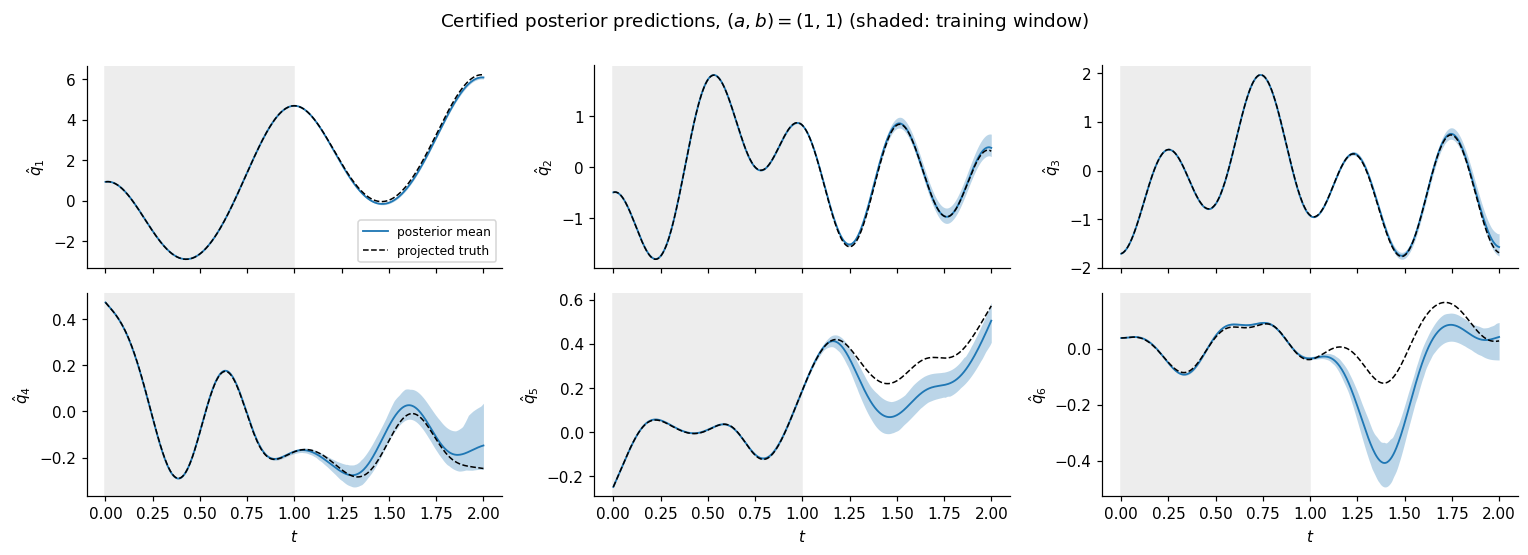

In [21]:
# Reduced coordinates: posterior mean and 95% band against the projected truth.
ci = 4                                   # which training trajectory to show
params, truth = CASES[ci]; E = ENS[ci]
qt = compress(truth)
fig, axes = plt.subplots(2, 3, figsize=(14, 5), sharex=True)
for i, ax in enumerate(axes.ravel()[:min(6, r)]):
    lo_, hi_ = np.quantile(E[:, i, :], [.025, .975], axis=0)
    ax.fill_between(t_truth, lo_, hi_, color="C0", alpha=.3, lw=0)
    ax.plot(t_truth, E[:, i, :].mean(0), "C0", lw=1.2, label="posterior mean")
    ax.plot(t_truth, qt[i], "k--", lw=1, label="projected truth")
    ax.axvspan(0, T_TRAIN, color="0.93", zorder=-1)
    ax.set_ylabel(rf"$\hat q_{{{i+1}}}$")
    if i == 0: ax.legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel("$t$")
fig.suptitle(f"Certified posterior predictions, $(a,b)={label(params)}$ (shaded: training window)", y=1.0)
plt.tight_layout(); plt.show()

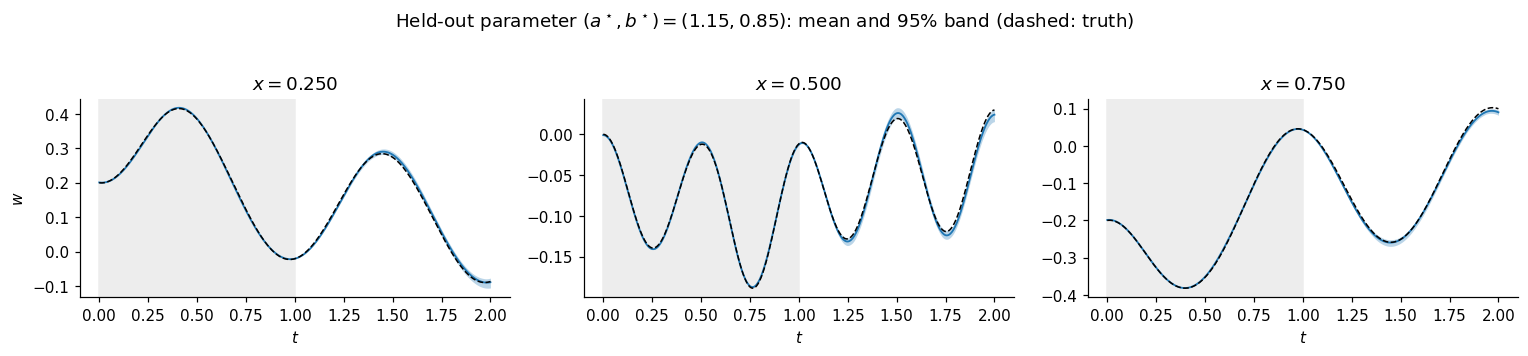

In [22]:
# Physical space: three locations, for the held-out parameter value.
params, truth = CASES[-1]; E = ENS[-1]
locs = [0.25, 0.5, 0.75]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.1), sharex=True)
for ax, xl in zip(axes, locs):
    j = int(np.argmin(np.abs(x - xl)))
    v_at_x = V[j]                                    # POD modes evaluated at x_j
    W = np.array([q_bar[j] + v_at_x @ q_hat for q_hat in E])   # w(x_j, t)
    lo_, hi_ = np.quantile(W, [.025, .975], axis=0)
    ax.fill_between(t_truth, lo_, hi_, color="C0", alpha=.3, lw=0)
    ax.plot(t_truth, W.mean(0), "C0", lw=1.2)
    ax.plot(t_truth, truth[j], "k--", lw=1)
    ax.axvspan(0, T_TRAIN, color="0.93", zorder=-1)
    ax.set(xlabel="$t$", title=f"$x = {x[j]:.3f}$")
axes[0].set_ylabel("$w$")
fig.suptitle(f"Held-out parameter $(a^\\star,b^\\star)={label(params)}$: mean and 95% band (dashed: truth)", y=1.03)
plt.tight_layout(); plt.show()

## 6. Comparison: the unconstrained posterior

The baseline is GP-BayesOpInf: the same model, the same Gaussian process estimates and the
same features, with energy preservation removed. Two things change.

**The prior scales are selected again.** Section 2.1 maximised the evidence under the
constrained model, which is the right choice there, and reusing those scales here would
handicap the baseline. Eq. (3) is applied once more with $\boldsymbol\Phi$ in place of
$\boldsymbol\Phi\mathbf T$ and $\mathbf P_0=\operatorname{diag}(\boldsymbol\gamma^2)$ --- that
is, with $\mathbf T=\mathbf I$.

**The certificate does not transfer.** Section 4 drops the cubic term in $\dot V$ because
$\hat{\mathbf q}^\top\widehat{\mathbf H}(\hat{\mathbf q}\otimes\hat{\mathbf q})=0$. Without the
constraint that term is not zero, so $\alpha$ and $\alpha^\star$ certify nothing here. What can
be measured instead is the constraint violation and the fraction of posterior draws whose
reduced model diverges.

In [23]:
# --- prior scales for the unconstrained model: eq. (3) with T = I ---
Phi_W_Phi = Phi.T @ (wvec[:, None]*Phi)        # Phi^T W Phi, the full n x n version
Phi_W_z   = Phi.T @ (wvec*zvec)                # Phi^T W z~

def log_evidence_unconstrained(gam):
    """Eq. (3) with no constraint, so P0 = diag(gamma^2) and Phi is used as it is."""
    gamma_sq = prior_scales(gam)**2
    P = Phi_W_Phi + np.diag(gamma_sq)
    logdet_P0 = np.sum(np.log(gamma_sq))       # P0 is diagonal here
    sign_P, logdet_P = np.linalg.slogdet(P)
    if sign_P <= 0:
        return -1e12
    mu_ = solve(P, Phi_W_z, assume_a="pos")
    return (-0.5*Nobs*np.log(2*np.pi)
            + 0.5*logdet_W
            + 0.5*logdet_P0
            - 0.5*logdet_P
            - 0.5*(z_W_z - mu_ @ (P @ mu_)))

t0 = time.time()
best_base = None
for log_gamma_0 in ([-2.]*4, [0.]*4, [2.]*4):
    result = minimize(lambda lg: -log_evidence_unconstrained(np.exp(lg)), log_gamma_0,
                      method="Nelder-Mead", options=dict(xatol=1e-4, fatol=1e-3, maxfev=2000))
    if best_base is None or result.fun < best_base.fun:
        best_base = result
gamma_base = np.exp(best_base.x)
print(f"evidence maximised in {time.time()-t0:.1f} s")
print(f"{'':12} {'constrained':>12} {'unconstrained':>14}")
print(f"{'log p(z~)':12} {-best.fun:12.2f} {-best_base.fun:14.2f}")
for name, g, gb in zip(["c", "A", "H", "B"], gamma, gamma_base):
    print(f"{'gamma_'+name:12} {g:12.4f} {gb:14.4f}")

evidence maximised in 1.4 s
              constrained  unconstrained
log p(z~)         5226.70        5790.62
gamma_c            0.7418         0.6542
gamma_A            0.4683         0.5319
gamma_H            1.0063         0.5839
gamma_B            0.1591         0.1561


In [24]:
# --- row posteriors of the unconstrained model, eq. (2) with the new scales ---
gvec_base = prior_scales(gamma_base)

Sig_base = np.zeros((n, n))
mu_base  = np.zeros(n)
Lchol_base = []
for i in range(r):
    block = slice(i*dof, (i+1)*dof)
    Sig_i = np.linalg.inv(DWD[i] + np.diag(gvec_base[block]**2))
    Sig_i = 0.5*(Sig_i + Sig_i.T)
    Sig_base[block, block] = Sig_i
    mu_base[block] = Sig_i @ DWz[i]
    Lchol_base.append(cholesky(Sig_i + 1e-14*np.eye(dof), lower=True))

A_base = mu_base.reshape(r, dof)[:, 1:1+r]
print(f"||C mu||: unconstrained {np.linalg.norm(Cmat@mu_base):.4e}   "
      f"constrained {np.linalg.norm(Cmat@mu_c):.3e}")
print(f"-lambda_max(sym A) = {-np.linalg.eigvalsh(0.5*(A_base+A_base.T)).max():+.4f} for this "
      f"posterior mean, which certifies nothing: the cubic term does not vanish.")

||C mu||: unconstrained 2.5806e+01   constrained 2.989e-14
-lambda_max(sym A) = -4.1346 for this posterior mean, which certifies nothing: the cubic term does not vanish.


In [25]:
# --- draws, with no correction applied ---
def draw_unconstrained(rng):
    """One draw of the unconstrained posterior: eq. (6) without the correction."""
    theta = np.zeros(n)
    for i in range(r):
        block = slice(i*dof, (i+1)*dof)
        theta[block] = mu_base[block] + Lchol_base[i] @ rng.standard_normal(dof)
    return theta

# Same seed as section 4, so the two methods see the same standard normal stream.
rng = np.random.default_rng(SEED)
theta_base = np.array([draw_unconstrained(rng) for _ in range(N_PRED)])
violation_base = np.linalg.norm(theta_base @ Cmat.T, axis=1)
print(f"||C theta|| over {N_PRED} draws: median {np.median(violation_base):.2f}   "
      f"max {violation_base.max():.2f}")
print(f"   (constrained draws: {violation.max():.3e})")

||C theta|| over 200 draws: median 28.84   max 32.91
   (constrained draws: 3.713e-14)


In [26]:
# --- the same N_PRED draws integrated over the same cases ---
t0 = time.time()
ENS_base = []
n_diverged = []
for params, truth in CASES:
    q0 = compress(truth[:, :1]).ravel()
    runs = []
    failures = 0
    for theta in theta_base:
        q_hat = integrate(theta, params, q0)
        if q_hat is None:
            failures += 1
        else:
            runs.append(q_hat)
    ENS_base.append(np.array(runs))
    n_diverged.append(failures)
print(f"{sum(e.shape[0] for e in ENS_base)} ROM solves in {time.time()-t0:.1f} s")
print(f"draws that diverged, per case: {n_diverged} out of {N_PRED} each "
      f"({sum(n_diverged)/(len(CASES)*N_PRED):.0%} overall)")

924 ROM solves in 16.1 s
draws that diverged, per case: [2, 60, 54, 93, 35, 32] out of 200 each (23% overall)


In [27]:
# Side by side.  The baseline errors are computed over the draws that survived, so they
# flatter it: the diverged draws are left out of its ensemble mean entirely.
print(f"{'(a,b)':>14} {'ours train':>11} {'ours pred':>10} "
      f"{'base train':>11} {'base pred':>10} {'diverged':>9}")
ERR_base = []
for ((params, truth), E_base, nd, e_ours) in zip(CASES, ENS_base, n_diverged, ERR):
    if E_base.shape[0] == 0:
        print(f"{label(params):>14} {e_ours[1]:11.4f} {e_ours[2]:10.4f} "
              f"{'-':>11} {'-':>10} {nd:9d}")
        ERR_base.append((params, np.nan, np.nan))
        continue
    Qm = decompress(E_base.mean(axis=0))
    b_tr = np.linalg.norm(Qm[:, mask_tr]-truth[:, mask_tr])/np.linalg.norm(truth[:, mask_tr])
    b_pr = np.linalg.norm(Qm[:,~mask_tr]-truth[:,~mask_tr])/np.linalg.norm(truth[:,~mask_tr])
    print(f"{label(params):>14} {e_ours[1]:11.4f} {e_ours[2]:10.4f} "
          f"{b_tr:11.4f} {b_pr:10.4f} {nd:9d}")
    ERR_base.append((params, b_tr, b_pr))

         (a,b)  ours train  ours pred  base train  base pred  diverged
    (0.6, 0.6)      0.0080     0.0620      0.0082     0.1214         2
    (1.4, 0.6)      0.0103     0.0834      0.0118     0.2442        60
    (0.6, 1.4)      0.0116     0.0702      0.0163     0.1207        54
    (1.4, 1.4)      0.0104     0.0964      0.0112     0.2442        93
        (1, 1)      0.0068     0.0711      0.0092     0.1625        35
  (1.15, 0.85)      0.0071     0.0745      0.0092     0.1938        32


## 7. Save

In [28]:
# Per-case ensemble summaries in reduced coordinates, so the paper figures can be
# drawn from this file without integrating anything again.
def summarise(E):
    """Mean and 95% interquantile band of an ensemble, shape (3, r, times)."""
    if E.shape[0] == 0:
        return np.full((3, r, t_truth.size), np.nan)
    lo, hi = np.quantile(E, [0.025, 0.975], axis=0)
    return np.stack([E.mean(axis=0), lo, hi])

ens_summary      = np.array([summarise(E) for E in ENS])        # (cases, 3, r, times)
ens_summary_base = np.array([summarise(E) for E in ENS_base])

np.savez_compressed(
    "results_Burgers1D.npz",
    t_truth=t_truth, V=V, q_bar=q_bar,
    ens_summary=ens_summary, ens_summary_base=ens_summary_base,
    theta_base=theta_base,
    gamma=gamma, mu=mu, mu_c=mu_c, C=Cmat, Kgain=Kg,
    alpha_plain=alpha_plain, alpha_shift=alpha_shift, radius=radius, certified=cert,
    centre=centre,
    p_hat=p_hat, cp_interval=np.array([lo, hi]), delta=DELTA, ubar=ubar,
    theta_certified=certified_draws,
    err=np.array([[e[1], e[2], e[3]] for e in ERR]),
    params=np.array([e[0] for e in ERR]),
    gamma_base=gamma_base, mu_base=mu_base,
    err_base=np.array([[e[1], e[2]] for e in ERR_base]),
    n_diverged=np.array(n_diverged), violation_base=violation_base,
)
print("saved results_Burgers1D.npz")

saved results_Burgers1D.npz


## 8. The figures of the paper

The two figures of the numerical section, drawn here with the settings the
manuscript uses. The script `problem1_figures.py` produces the same two as PDFs
from `results_Burgers1D.npz`; the code below is the same, kept inline so that this
notebook reads on its own.


In [29]:
import matplotlib as mpl

PAPER_RC = {
    "font.family": "serif", "font.size": 8,
    "axes.labelsize": 8, "axes.titlesize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "lines.linewidth": 1.0, "pdf.fonttype": 42,
}
C_CON, C_UNC = "#0072B2", "#D55E00"
MEAN, LO, HI = 0, 1, 2

def prediction_figure(t, V, summary, summary_base, truth, params):
    """The two posteriors at one parameter value, leading reduced coordinates."""
    q_truth = V.T @ (truth - q_bar[:, None])
    fig, axes = plt.subplots(1, 3, figsize=(6.3, 2.0), sharex=True)
    for i, ax in enumerate(axes):
        ax.axvspan(0, T_TRAIN, color="0.94", lw=0, zorder=-2)
        for S, color, style, name in ((summary_base, C_UNC, "-.", "unconstrained"),
                                      (summary,      C_CON, "-",  "constrained")):
            ax.fill_between(t, S[LO, i], S[HI, i], color=color, alpha=0.22, lw=0)
            ax.plot(t, S[MEAN, i], color=color, ls=style, label=name)
        ax.plot(t, q_truth[i], color="0.1", ls=(0, (1.2, 1.2)), lw=0.8,
                label="projected truth")
        ax.set_xlabel(r"$t$")
        ax.set_ylabel(rf"$\hat q_{{{i+1}}}$")
        ax.set_xlim(t[0], t[-1])
        # Scaled to the truth and the constrained band.  A few surviving
        # unconstrained draws spike as t approaches 2 and their band leaves the axes.
        span = np.concatenate([q_truth[i], summary[LO, i], summary[HI, i]])
        pad = 0.18*(span.max() - span.min())
        ax.set_ylim(span.min() - pad, span.max() + pad)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False,
               handlelength=1.8, bbox_to_anchor=(0.5, 1.07))
    fig.tight_layout(pad=0.3)
    return fig

def certificate_figure(alpha, alpha_star, p_hat):
    """The two certificates over the posterior draws."""
    fig, axes = plt.subplots(1, 2, figsize=(6.3, 1.9))
    for ax, v, color, xlabel in (
            (axes[0], alpha, "0.55",
             r"$\alpha=-\lambda_{\max}(\mathrm{sym}\,\widehat{A})$"),
            (axes[1], alpha_star, C_CON, r"$\alpha^\star$")):
        ax.hist(v, bins=60, color=color, lw=0)
        ax.axvline(0.0, color=C_UNC, lw=0.9)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("draws")
    axes[0].set_title("plain certificate")
    axes[1].set_title(rf"shifted certificate, $\hat p_\delta={p_hat:.3f}$")
    fig.tight_layout(pad=0.3)
    return fig

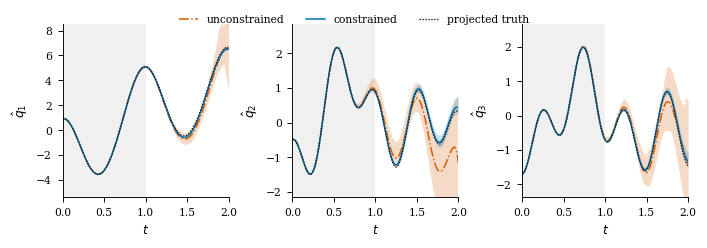

In [30]:
# Figure of the paper: the two posteriors at the held-out parameter value.
case = -1
params, truth = CASES[case]
with plt.rc_context(PAPER_RC):
    fig = prediction_figure(t_truth, V, ens_summary[case], ens_summary_base[case],
                            truth, params)
    fig.savefig("fig_prob1_prediction.pdf", bbox_inches="tight")
    plt.show()

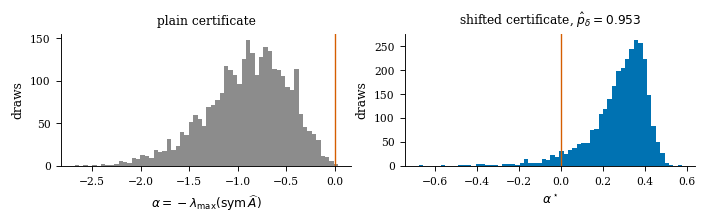

In [31]:
# Figure of the paper: the two certificates over the 3000 draws.
with plt.rc_context(PAPER_RC):
    fig = certificate_figure(alpha_plain, alpha_shift, p_hat)
    fig.savefig("fig_prob1_certificates.pdf", bbox_inches="tight")
    plt.show()